# 02. Энергетика: устойчивость «умной» электросети (Smart Grid)

**Дисциплина:** «Управление и аналитика данных на предприятии» · СПбПУ, ИПМЭиТ · Лекция 7

**Профиль:** Менеджмент в энергетике

**Бизнес-вопрос:** Можно ли по параметрам участников энергосети (время реакции на цену, мощность, ценовая эластичность) заранее определить, станет ли сеть неустойчивой, — и какие параметры менеджмент может регулировать (тарифы, требования к оборудованию)?

**Данные:** `grid_stability.csv` — 10 000 сценариев сети «1 производитель + 3 потребителя» с децентрализованным управлением по цене (Decentral Smart Grid Control). Источник: [UCI ML Repository, Electrical Grid Stability Simulated Data](https://archive.ics.uci.edu/dataset/471/electrical+grid+stability+simulated+data), Arzamasov et al., 2018, CC BY 4.0.

---
Ноутбук построен по единому сценарию из 10 шагов (см. лекцию 7): *вопрос → загрузка → паспорт данных → очистка → разведка → связи и тренды → постановка ML-задачи → train/test → модель и базовая линия → качество и вывод для бизнеса*. Запуск: «Среда выполнения → Выполнить всё». Данные загружаются по постоянной ссылке с GitHub — ничего загружать вручную не нужно.

## Шаг 1. Вопрос и гипотеза

| признак | смысл |
|---|---|
| `tau1…tau4` | время реакции участника на изменение цены, с (1 — производитель, 2–4 — потребители) |
| `p1…p4` | номинальная мощность: p1 > 0 производство, p2–p4 < 0 потребление |
| `g1…g4` | коэффициент ценовой эластичности участника (γ) |
| `stab` | максимальный действительный корень характеристического уравнения (> 0 — неустойчиво) |
| `stabf` | метка: stable / unstable → **целевая переменная** |

**Гипотеза H1:** чем медленнее участники реагируют на цену (больше τ), тем выше риск неустойчивости.

In [1]:
# Шаг 0. Подключаем библиотеки (как в базовом примере)
import numpy as np                 # вычисления
import pandas as pd                # таблицы
import seaborn as sns              # графики
import matplotlib.pyplot as plt    # графики

sns.set_theme(style="whitegrid", palette=["#37B34A", "#244128", "#7248A0", "#F39768", "#DA4927"])
pd.set_option("display.max_columns", 30)

## Шаги 2–3. Загрузка и паспорт данных

In [2]:
grid = pd.read_csv("https://raw.githubusercontent.com/alejanro85/uad-lecture7-ml/main/data/grid_stability.csv")
print(grid.shape); print("Пропусков:", grid.isna().sum().sum())
grid.describe().T.round(2)

(10000, 14)
Пропусков: 0


,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.25,2.74,0.50,2.87,5.25,7.62,10.00
tau2,10000.0,5.25,2.74,0.50,2.88,5.25,7.62,10.00
tau3,10000.0,5.25,2.74,0.50,2.88,5.25,7.62,10.00
tau4,10000.0,5.25,2.74,0.50,2.87,5.25,7.62,10.00
p1,10000.0,3.75,0.75,1.58,3.22,3.75,4.28,5.86
p2,10000.0,-1.25,0.43,-2.00,-1.62,-1.25,-0.87,-0.50
p3,10000.0,-1.25,0.43,-2.00,-1.63,-1.25,-0.88,-0.50
p4,10000.0,-1.25,0.43,-2.00,-1.62,-1.25,-0.88,-0.50
g1,10000.0,0.52,0.27,0.05,0.29,0.53,0.76,1.00
g2,10000.0,0.53,0.27,0.05,0.29,0.53,0.76,1.00


In [3]:
grid["stabf"].value_counts(normalize=True).round(3)

stabf
unstable    0.638
stable      0.362
Name: proportion, dtype: float64

**Вывод:** 10 000 сценариев, 14 столбцов, пропусков нет (данные смоделированы). Неустойчивых сценариев — 63,8%: классы не сбалансированы, но не критично.

## Шаг 4. Подготовка: убираем «утечку ответа» и дубли информации

* `stab` — это численная версия ответа. Если оставить её в признаках, модель будет «списывать» → **data leakage**.
* `p1 = −(p2 + p3 + p4)` — линейно зависит от других, добавляет только мультиколлинеарность.

In [4]:
print("Проверка баланса мощности:", np.allclose(grid["p1"], -(grid["p2"] + grid["p3"] + grid["p4"])))
X = grid.drop(columns=["stab", "stabf", "p1"])
y = (grid["stabf"] == "unstable").astype(int)      # 1 — неустойчиво
X.columns.tolist()

Проверка баланса мощности: True


['tau1', 'tau2', 'tau3', 'tau4', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4']

## Шаги 5–6. Разведка: какие параметры связаны с неустойчивостью?

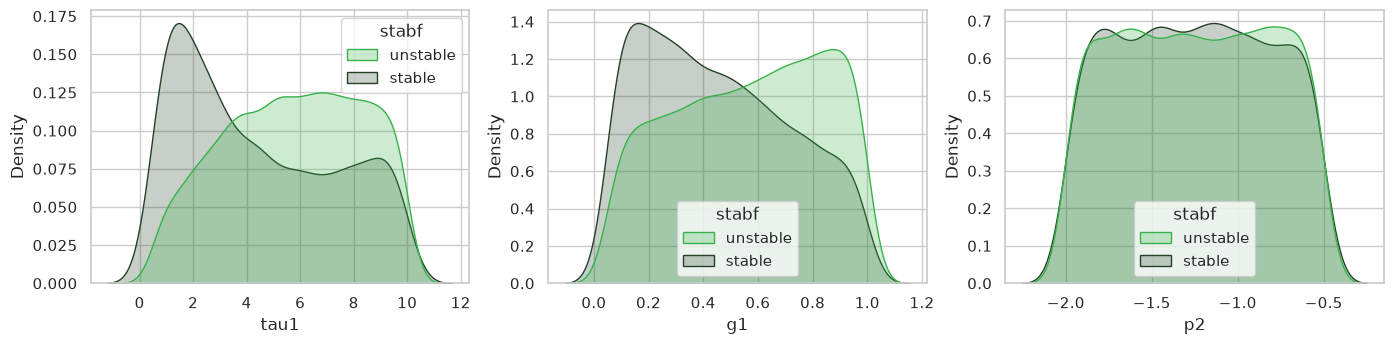

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col in zip(ax, ["tau1", "g1", "p2"]):
    sns.kdeplot(data=grid, x=col, hue="stabf", fill=True, common_norm=False, ax=a)
plt.tight_layout(); plt.show()

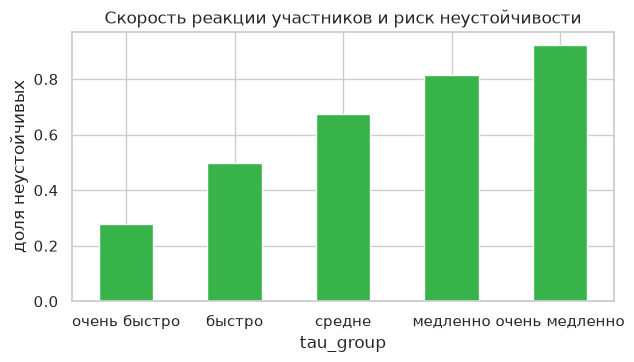

In [6]:
share = grid.assign(tau_mean=grid[["tau1","tau2","tau3","tau4"]].mean(axis=1))
share["tau_group"] = pd.qcut(share["tau_mean"], 5, labels=["очень быстро", "быстро", "средне", "медленно", "очень медленно"])
ax = share.groupby("tau_group", observed=True)["stabf"].apply(lambda s: (s == "unstable").mean()).plot.bar(color="#37B34A", figsize=(7, 3.5))
ax.set_ylabel("доля неустойчивых"); ax.set_title("Скорость реакции участников и риск неустойчивости"); plt.xticks(rotation=0); plt.show()

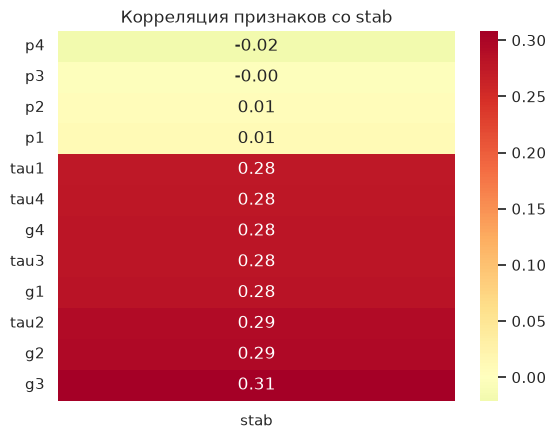

In [7]:
sns.heatmap(grid.drop(columns=["stabf"]).corr()[["stab"]].drop("stab").sort_values("stab"),
            annot=True, fmt=".2f", cmap="RdYlGn_r", center=0)
plt.title("Корреляция признаков со stab"); plt.show()

**Вывод по шагам 5–6:** гипотеза H1 подтверждается: в группе «очень медленной» реакции доля неустойчивых сценариев — 92%, в группе «очень быстрой» — 28% (в 3,3 раза меньше). Эластичность γ тоже положительно связана с неустойчивостью. Мощность p почти не влияет.

## Шаги 7–10. Модель и оценка качества

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

def quality(y_true, y_pred, y_proba=None, name="модель"):
    """Печатает ключевые метрики качества классификатора одной строкой."""
    line = (f"{name:<28} accuracy={accuracy_score(y_true, y_pred):.3f}  "
            f"precision={precision_score(y_true, y_pred, zero_division=0):.3f}  "
            f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")
    if y_proba is not None:
        line += f"  ROC-AUC={roc_auc_score(y_true, y_proba):.3f}"
    print(line)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
quality(y_te, DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr).predict(X_te), name="Базовая линия")
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
pred, proba = model.predict(X_te), model.predict_proba(X_te)[:, 1]
quality(y_te, pred, proba, name="Логистическая регрессия")

Базовая линия                accuracy=0.638  precision=0.638  recall=1.000  f1=0.779
Логистическая регрессия      accuracy=0.817  precision=0.836  recall=0.887  f1=0.861  ROC-AUC=0.891


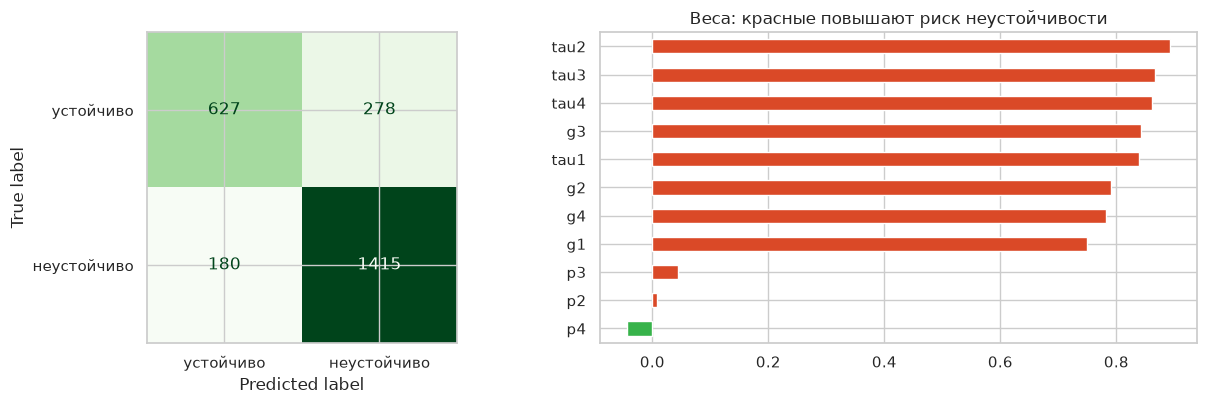

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["устойчиво", "неустойчиво"]).plot(ax=ax[0], cmap="Greens", colorbar=False)
coef = pd.Series(model[-1].coef_[0], index=X.columns).sort_values()
coef.plot.barh(ax=ax[1], color=["#37B34A" if v < 0 else "#DA4927" for v in coef])
ax[1].set_title("Веса: красные повышают риск неустойчивости")
plt.tight_layout(); plt.show()

## Итоговые выводы для бизнеса

1. Модель распознаёт неустойчивые сценарии с **accuracy ≈ 82% против 64%** у базовой линии (ROC-AUC ≈ 0,89).
2. **Главные управляемые факторы риска** — время реакции участников (τ) и их ценовая эластичность (γ). Это прямые рычаги для менеджмента: требования к скорости систем учёта/управления у потребителей, дизайн тарифа (насколько резко цена реагирует на дисбаланс).
3. **Демонстрация методической ошибки:** если не удалить `stab`, точность будет ~100% — но это «списывание», а не прогноз. Проверяйте признаки на утечку!
4. **Ограничения:** данные смоделированы; линейная модель не ловит взаимодействия факторов — следующий шаг: дерево решений / градиентный бустинг и данные реальной сети.